# 📡 정보통신개론 개별 과제 제출 양식
## 내 목소리로 실습하는 AM · FM 변조와 PCM 부호화

| 항목 | 내용 |
|---|---|
| 제출물 | 이 노트북(실행 결과가 모두 남아 있는 상태) — `.ipynb` 파일 또는 Colab 공유 링크 |
| 파일 이름 | `정보통신개론_번호_이름.ipynb` |
| 진행 방법 | **설계(값 선택·기술) → 코드 작성 → 실행 결과 확인 → 결과 기록** 순서로 각 단계를 작성 |

### 작성 방법
1. **파일 → 드라이브에 사본 저장** 후 작업합니다.
2. 📝 표시 칸(마크다운 셀)은 **더블클릭**하여 `(작성)` 부분을 채웁니다.
3. 💻 표시 칸(코드 셀)에는 **직접 코드를 작성**하고 실행합니다. 셀 맨 위 주석의 **"반드시 나와야 할 것"** 이 출력되어야 합니다.
4. **변조·부호화 코드를 작성하기 전에 반드시 설계표(사용할 주파수, 변조지수 등)를 먼저 작성**합니다.
5. 모든 그래프 제목에는 **본인 번호와 이름**이 들어가도록 합니다.
6. 제출 전 **런타임 → 모두 실행**으로 오류 없이 결과가 나오는지 확인합니다.

## 1. 제출자 정보 📝

| 항목 | 내용 |
|---|---|
| 번호 | 03 |
| 이름 | 권신협 |
| 제출일 | 2026년 10월 22일 |

---
## 2. 본인 음성 신호 입력

In [1]:
# ===== 2-2. 라이브러리 불러오기 · 기본 설정 =====
# [실행 결과] 라이브러리, 한글 폰트 설정, 실행 환경 확인
import os, sys, glob, subprocess, hashlib, base64
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import signal
from scipy.io import wavfile
from scipy.special import erfc
from IPython.display import Audio, Javascript, display

# Colab 전용 기능은 Colab에서만 가져온다.
try:
    from google.colab import output, files
    IN_COLAB = True
except ImportError:
    output = None
    files = None
    IN_COLAB = False

# 이미 설치된 한글 글꼴을 찾는다. Colab에서 없으면 설치를 시도하되 실패해도 실행은 계속한다.
font_files = (
    glob.glob('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
    + glob.glob('/usr/share/fonts/**/NotoSansCJK*-Regular.ttc', recursive=True)
    + glob.glob('/usr/share/fonts/**/NanumGothic.ttf', recursive=True)
)
if not font_files and IN_COLAB:
    subprocess.run('apt-get -qq -y install fonts-nanum > /dev/null 2>&1', shell=True, check=False)
    font_files = glob.glob('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
if font_files:
    try:
        fm.fontManager.addfont(font_files[0])
        plt.rc('font', family=fm.FontProperties(fname=font_files[0]).get_name())
    except Exception as exc:
        print('한글 글꼴 자동 설정을 건너뜁니다:', exc)

plt.rcParams.update({
    'axes.unicode_minus': False,
    'figure.figsize': (10, 3.2),
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.color': '#dddddd',
    'axes.prop_cycle': plt.cycler(color=['black', 'gray', 'darkgray']),
})

def play(x, fs, label=''):
    """노트북에서 배열을 소리로 재생한다."""
    print(f'[소리 재생] {label}')
    display(Audio(np.asarray(x, dtype=float), rate=int(fs)))

def spectrum(x, fs):
    """주파수 스펙트럼을 최대값 기준 dB로 반환한다."""
    x = np.asarray(x, dtype=float).ravel()
    if x.size == 0:
        raise ValueError('스펙트럼을 계산할 신호가 비어 있습니다.')
    X = np.abs(np.fft.rfft(x * np.hanning(len(x)))) + 1e-12
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, 20 * np.log10(X / np.max(X))

print('환경 설정 완료 / Colab 환경:', IN_COLAB)


환경 설정 완료 / Colab 환경: False


In [2]:
# ===== 2-3. 음성 신호 입력 모듈 =====
# SOURCE = 'upload' : Colab에서 음성 파일 업로드
# SOURCE = 'record' : Colab 브라우저 마이크 녹음
# SOURCE = 'sample' : 첨부 실습 파일에 있는 내부 합성 음성 사용
SOURCE = 'upload'
RECORD_SEC = 4
FS_ANALOG = 44100
MAX_SEC = 4


def to_wav(src, dst='voice.wav'):
    """입력 파일을 모노 44.1 kHz WAV로 바꾸어 읽는다."""
    subprocess.run(
        ['ffmpeg', '-y', '-loglevel', 'error', '-i', src,
         '-ac', '1', '-ar', str(FS_ANALOG), dst],
        check=True,
    )
    _, data = wavfile.read(dst)
    return data

RECORD_JS = """
const sleep = t => new Promise(r => setTimeout(r, t));
const toB64 = blob => new Promise(res => { const rd = new FileReader();
  rd.onloadend = () => res(rd.result); rd.readAsDataURL(blob); });
var record = async (sec) => {
  const stream = await navigator.mediaDevices.getUserMedia({audio: true});
  const rec = new MediaRecorder(stream); const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.start(); await sleep(sec * 1000); rec.stop();
  await new Promise(r => rec.onstop = r);
  stream.getTracks().forEach(t => t.stop());
  return await toB64(new Blob(chunks));
}
"""


def record(sec):
    """Colab 브라우저 마이크로 녹음한다."""
    from google.colab.output import eval_js
    display(Javascript(RECORD_JS))
    print(f'{sec}초 동안 녹음합니다. 지금 말씀하세요...')
    data = eval_js(f'record({sec})')
    with open('rec.webm', 'wb') as f:
        f.write(base64.b64decode(data.split(',')[1]))
    print('녹음 완료')
    return to_wav('rec.webm')


def sample_voice(sec=3.0, fs=FS_ANALOG):
    """첨부 실습 파일에 있는 방식으로 합성 모음 음성을 만든다."""
    sample_t = np.arange(int(sec * fs)) / fs
    f0 = 140 + 20 * np.sin(2 * np.pi * 0.6 * sample_t) + 4 * np.sin(2 * np.pi * 5.5 * sample_t)
    pulses = np.diff(np.floor(np.cumsum(f0) / fs), prepend=0)
    src = signal.lfilter([1], [1, -0.95], pulses)
    vowels = [(800, 1200, 2500), (500, 1900, 2500), (300, 2300, 3000),
              (500, 900, 2400), (330, 800, 2300)]
    seg = len(sample_t) // len(vowels)
    out = []
    for k, formants in enumerate(vowels):
        y = src[k * seg:(k + 1) * seg]
        for formant in formants:
            r = np.exp(-np.pi * 90 / fs)
            y = signal.lfilter(
                [1 - r],
                [1, -2 * r * np.cos(2 * np.pi * formant / fs), r * r],
                y,
            )
        env = np.sin(np.linspace(0, np.pi, len(y))) ** 0.6
        out.append(y * env)
    # samples 수가 나누어떨어지지 않는 나머지 부분도 안전하게 포함한다.
    used = seg * len(vowels)
    if used < len(src):
        out.append(src[used:])
    return np.concatenate(out)


if SOURCE == 'upload' and IN_COLAB:
    uploaded = files.upload()
    if not uploaded:
        raise ValueError('음성 파일이 선택되지 않았습니다. SOURCE를 record 또는 sample로 바꾸어 실행하세요.')
    x = to_wav(next(iter(uploaded)))
elif SOURCE == 'record' and IN_COLAB:
    x = record(RECORD_SEC)
else:
    if SOURCE != 'sample':
        print('Colab 녹음/업로드 기능을 사용할 수 없어 내부 합성 예제 음성을 사용합니다.')
    x = sample_voice()

# 모노 변환, 무음 앞부분 제거, 길이 제한 및 정규화
x = np.asarray(x, dtype=float)
if x.ndim > 1:
    x = x.mean(axis=1)
if x.size == 0 or float(np.max(np.abs(x))) < 1e-12:
    print('입력 신호가 비어 있거나 무음이므로 내부 합성 예제 음성을 사용합니다.')
    x = sample_voice()
peak = float(np.max(np.abs(x)))
x = x / peak
active = np.flatnonzero(np.abs(x) > 0.05)
start = int(active[0]) if active.size else 0
x = x[start:start + MAX_SEC * FS_ANALOG]
if x.size == 0:
    x = sample_voice()
x_peak = float(np.max(np.abs(x)))
if x_peak > 1e-12:
    x = 0.95 * x / x_peak

t_analog = np.arange(len(x)) / FS_ANALOG
ZOOM = max(1, min(int(0.010 * FS_ANALOG), len(x)))
energy_window = np.convolve(x ** 2, np.ones(ZOOM), mode='valid')
z0 = int(np.argmax(energy_window))
z1 = min(z0 + ZOOM, len(x))

print(f'길이 {len(x) / FS_ANALOG:.2f}초, 표본 {len(x):,}개 (FS_ANALOG = {FS_ANALOG:,} Hz)')
play(x, FS_ANALOG, '원본 음성')


Colab 녹음/업로드 기능을 사용할 수 없어 내부 합성 예제 음성을 사용합니다.
길이 2.96초, 표본 130,740개 (FS_ANALOG = 44,100 Hz)
[소리 재생] 원본 음성


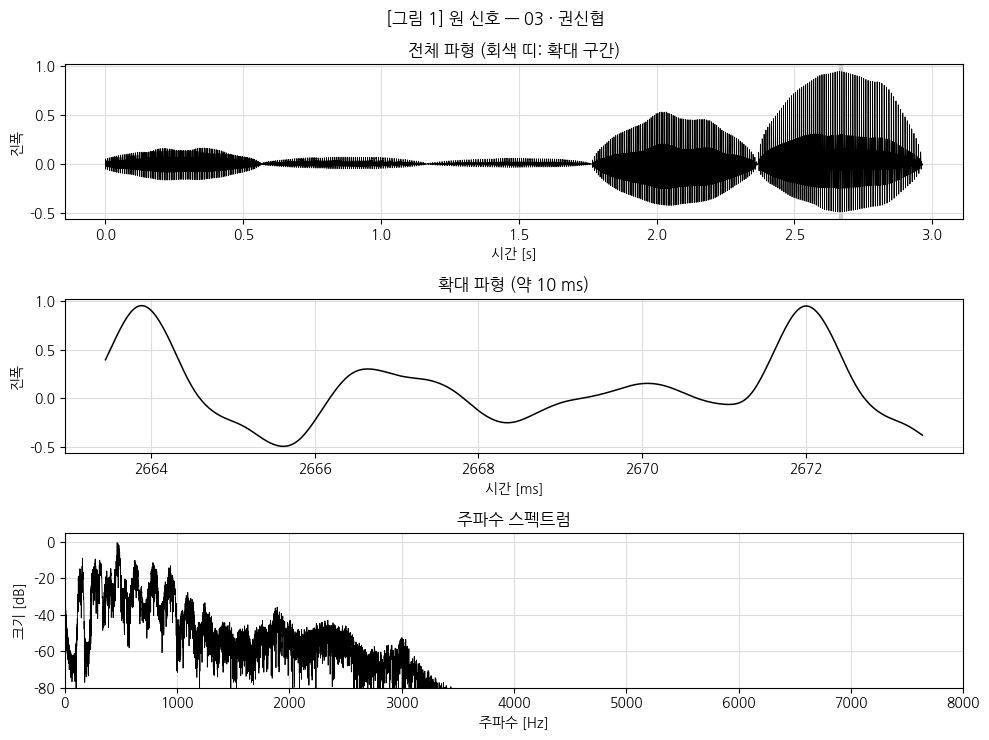

In [3]:
# ===== 2-4. [그림 1] 원 신호(메시지 신호) 그래프 =====
fig, ax = plt.subplots(3, 1, figsize=(10, 7.5))
ax[0].plot(t_analog, x, lw=0.6)
ax[0].axvspan(t_analog[z0], t_analog[min(z1, len(x) - 1)], color='gray', alpha=0.3)
ax[0].set(title='전체 파형 (회색 띠: 확대 구간)', xlabel='시간 [s]', ylabel='진폭')
ax[1].plot(t_analog[z0:z1] * 1000, x[z0:z1], lw=1.1)
ax[1].set(title='확대 파형 (약 10 ms)', xlabel='시간 [ms]', ylabel='진폭')
f, X = spectrum(x, FS_ANALOG)
ax[2].plot(f, X, lw=0.6)
ax[2].set(title='주파수 스펙트럼', xlabel='주파수 [Hz]', ylabel='크기 [dB]',
          xlim=(0, 8000), ylim=(-80, 5))
fig.suptitle('[그림 1] 원 신호 — 03 · 권신협')
plt.tight_layout()
plt.show()


---
## 3. AM 변조

$$s_{AM}(t) = A_c\,[\,1 + m\cdot x(t)\,]\cos(2\pi f_c t)$$

### 3-1. AM 변조 설계 📝

| 항목 | 기호 | 내가 선택한 값 | 단위 | 이 값을 선택한 이유 |
|---|---|---:|---|---|
| 반송파 주파수 | fc | 10000 | Hz | 음성 대역과 측파대가 샘플링 주파수 안에 들어오도록 선택 |
| 반송파 진폭 | Ac | 1.0 | V | 진폭 변화를 비교하기 쉬운 기준값 |
| 변조지수 | m | 0.8 | - | 1보다 작아 과변조를 피하도록 선택 |
| 메시지 최고 주파수 | fm | 3400 | Hz | 음성 대역 상한 F_HIGH와 일치시킴 |
| 변조에 사용할 샘플링 주파수 | Fs | 48000 | Hz | fc + fm = 13400 Hz가 Fs/2 = 24000 Hz보다 작음 |


In [4]:
# ===== 3-2. AM 변조 파라미터 선언 =====
FC = 10000       # 반송파 주파수 [Hz]
Ac = 1.0         # 반송파 진폭 [V]
M = 0.8          # 변조지수
fm = 3400        # 메시지 최고 주파수 [Hz]
FS = 48000       # 변조용 샘플링 주파수 [Hz]
F_LOW = 300      # 음성 대역 하한 [Hz]
F_HIGH = 3400    # 음성 대역 상한 [Hz]
SNR_DB = 30      # 참고용 채널 SNR [dB]

print(f'FC = {FC:,} Hz')
print(f'Ac = {Ac:.1f} V')
print(f'M = {M:.2f}')
print(f'fm = {fm:,} Hz')
print(f'FS = {FS:,} Hz')
print(f'샘플링 확인: FC + fm = {FC + fm:,} Hz < FS/2 = {FS / 2:,.0f} Hz')


FC = 10,000 Hz
Ac = 1.0 V
M = 0.80
fm = 3,400 Hz
FS = 48,000 Hz
샘플링 확인: FC + fm = 13,400 Hz < FS/2 = 24,000 Hz


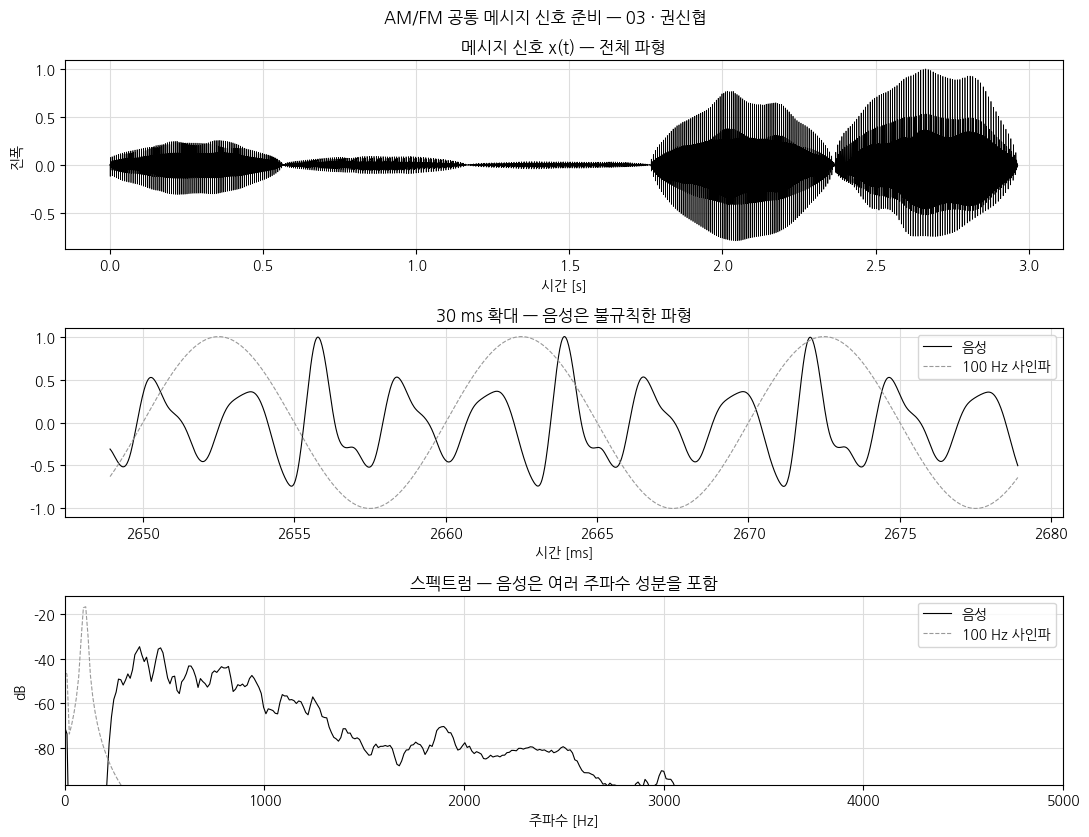

메시지 신호 준비 완료: 142,303 표본, 2.96초, 범위 -0.791 ~ 1.000
[소리 재생] 필터링된 메시지 신호


In [5]:
# ===== 3-3. AM 변조에 사용할 메시지 신호 준비 =====
# 원 입력은 FS_ANALOG Hz이므로, 변조 처리 전에 반드시 FS Hz로 변환한다.
common = int(np.gcd(FS, FS_ANALOG))
up = FS // common
down = FS_ANALOG // common
x_fs = signal.resample_poly(x, up, down)

def safe_sosfiltfilt(sos, values):
    """짧은 신호에서도 pad 길이 오류 없이 필터링한다."""
    values = np.asarray(values, dtype=float)
    min_length = 3 * (2 * len(sos) + 1)
    if len(values) <= min_length:
        return signal.sosfilt(sos, values)
    return signal.sosfiltfilt(sos, values)

sos_bp = signal.butter(6, [F_LOW, F_HIGH], btype='bandpass', fs=FS, output='sos')
msg = safe_sosfiltfilt(sos_bp, x_fs)
msg_peak = float(np.max(np.abs(msg)))
if msg_peak < 1e-12:
    raise ValueError('필터 처리 후 메시지 신호가 무음입니다. 음성 입력을 확인하세요.')
msg = msg / msg_peak                       # -1 ~ +1 정규화
t = np.arange(len(msg)) / FS

def spectrum_db(sig, fs=FS):
    sig = np.asarray(sig, dtype=float).ravel()
    nperseg = min(4096, len(sig))
    f_s, p_s = signal.welch(sig, fs=fs, nperseg=nperseg)
    return f_s, 10 * np.log10(p_s + 1e-15)

# 참고용 100 Hz 사인파와 실제 음성의 파형/스펙트럼 비교
sine = np.sin(2 * np.pi * 100 * t)
i0 = int(np.argmax(np.abs(msg)))
w = min(int(0.03 * FS), len(msg))
s0 = max(0, min(i0 - w // 2, len(msg) - w))

fig, ax = plt.subplots(3, 1, figsize=(11, 8.5))
ax[0].plot(t, msg, 'k', lw=0.5)
ax[0].set_title('메시지 신호 x(t) — 전체 파형')
ax[0].set_xlabel('시간 [s]'); ax[0].set_ylabel('진폭')
ax[1].plot(t[s0:s0+w] * 1000, msg[s0:s0+w], 'k', lw=0.8, label='음성')
ax[1].plot(t[s0:s0+w] * 1000, sine[s0:s0+w], color='0.6', ls='--', lw=0.8, label='100 Hz 사인파')
ax[1].set_title('30 ms 확대 — 음성은 불규칙한 파형')
ax[1].set_xlabel('시간 [ms]'); ax[1].legend(loc='upper right')
f_msg, P_msg_db = spectrum_db(msg)
f_sine, P_sine_db = spectrum_db(sine)
ax[2].plot(f_msg, P_msg_db, 'k', lw=0.8, label='음성')
ax[2].plot(f_sine, P_sine_db, color='0.6', ls='--', lw=0.8, label='100 Hz 사인파')
ax[2].set_xlim(0, 5000); ax[2].set_ylim(max(P_msg_db.max(), P_sine_db.max()) - 80, max(P_msg_db.max(), P_sine_db.max()) + 5)
ax[2].set_title('스펙트럼 — 음성은 여러 주파수 성분을 포함')
ax[2].set_xlabel('주파수 [Hz]'); ax[2].set_ylabel('dB'); ax[2].legend()
fig.suptitle('AM/FM 공통 메시지 신호 준비 — 03 · 권신협')
plt.tight_layout(); plt.show()
print(f'메시지 신호 준비 완료: {len(msg):,} 표본, {len(msg) / FS:.2f}초, 범위 {msg.min():.3f} ~ {msg.max():.3f}')
play(msg, FS, '필터링된 메시지 신호')


설계 변조지수 m = 0.800
포락선 최대값 Amax = 1.8000 V
포락선 최소값 Amin = 0.3674 V
측정 변조지수 = (Amax-Amin)/(Amax+Amin) = 0.6610
과변조 여부: 과변조 아님 (m ≤ 1)


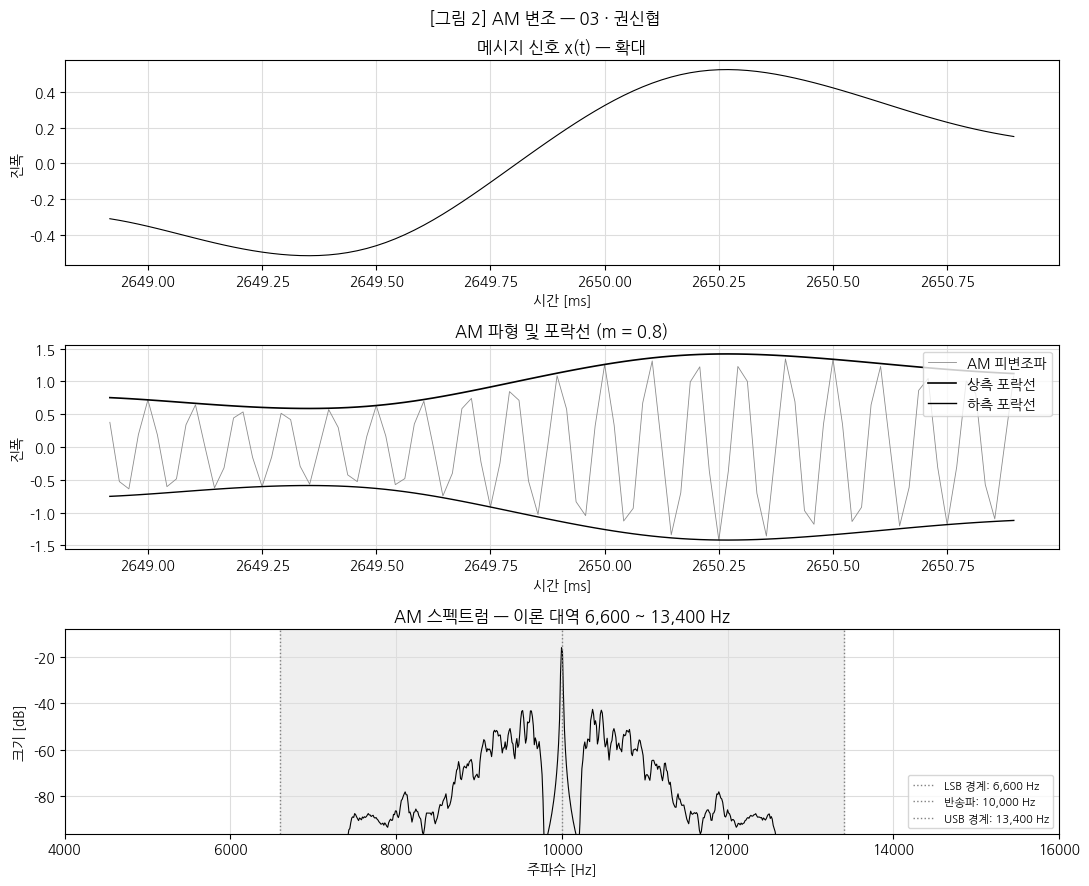

In [6]:
# ===== 3-4. [그림 2] AM 변조 그래프 =====
carrier = Ac * np.cos(2 * np.pi * FC * t)
envelope = Ac * (1 + M * msg)
am = (1 + M * msg) * carrier
am_tx = am / (np.max(np.abs(am)) + 1e-12)

Amax = float(np.max(envelope))
Amin = float(np.min(envelope))
measured_m = (Amax - Amin) / (Amax + Amin) if (Amax + Amin) > 1e-12 else float('nan')
print(f'설계 변조지수 m = {M:.3f}')
print(f'포락선 최대값 Amax = {Amax:.4f} V')
print(f'포락선 최소값 Amin = {Amin:.4f} V')
print(f'측정 변조지수 = (Amax-Amin)/(Amax+Amin) = {measured_m:.4f}')
print('과변조 여부:', '과변조 가능' if M > 1 else '과변조 아님 (m ≤ 1)')

fig, ax = plt.subplots(3, 1, figsize=(11, 9))
view = min(int(0.002 * FS), len(t))
view_start = max(0, min(s0, len(t) - view))
view_end = view_start + view
ax[0].plot(t[view_start:view_end] * 1000, msg[view_start:view_end], 'k', lw=0.8)
ax[0].set_title('메시지 신호 x(t) — 확대'); ax[0].set_xlabel('시간 [ms]'); ax[0].set_ylabel('진폭')
ax[1].plot(t[view_start:view_end] * 1000, am[view_start:view_end], color='0.55', lw=0.6, label='AM 피변조파')
ax[1].plot(t[view_start:view_end] * 1000, envelope[view_start:view_end], 'k', lw=1.2, label='상측 포락선')
ax[1].plot(t[view_start:view_end] * 1000, -envelope[view_start:view_end], 'k', lw=1.0, label='하측 포락선')
ax[1].set_title(f'AM 파형 및 포락선 (m = {M})'); ax[1].set_xlabel('시간 [ms]'); ax[1].set_ylabel('진폭'); ax[1].legend(loc='upper right')
f_am, P_am_db = spectrum_db(am)
ax[2].plot(f_am, P_am_db, 'k', lw=0.8)
for fx, label in [(FC - F_HIGH, 'LSB 경계'), (FC, '반송파'), (FC + F_HIGH, 'USB 경계')]:
    ax[2].axvline(fx, color='0.5', ls=':', lw=1, label=f'{label}: {fx:,} Hz')
ax[2].axvspan(FC - F_HIGH, FC + F_HIGH, color='0.8', alpha=0.3)
ax[2].set_xlim(FC - 6000, FC + 6000)
ax[2].set_ylim(P_am_db.max() - 80, P_am_db.max() + 8)
ax[2].set_title(f'AM 스펙트럼 — 이론 대역 {FC-F_HIGH:,} ~ {FC+F_HIGH:,} Hz')
ax[2].set_xlabel('주파수 [Hz]'); ax[2].set_ylabel('크기 [dB]'); ax[2].legend(loc='lower right', fontsize=8)
fig.suptitle('[그림 2] AM 변조 — 03 · 권신협')
plt.tight_layout(); plt.show()


### 3-5. AM 결과 기록 📝

| 항목 | 설계값(예상) | 실행 결과 | 일치 여부 / 차이 이유 |
|---|---|---|---|
| 변조지수 m | 0.8 | 위 셀의 측정값 | 입력 음성의 양·음 최대 크기가 다르면 측정값과 0.8이 조금 다를 수 있음 |
| 대역폭 B | 2 × 3400 = 6800 Hz | 스펙트럼에서 확인 | 음성 스펙트럼의 실제 에너지는 전체 이론 대역에 균일하지 않음 |
| 측파대 범위 | 하측 6600~9700 Hz, 상측 10300~13400 Hz | 스펙트럼에서 확인 | 음성의 300~3400 Hz 대역을 반송파 양쪽으로 이동시킴 |
| 과변조 여부 | 과변조 아님 (m=0.8 < 1) | 위 셀의 출력 | 포락선이 음수가 되지 않음 |


---
## 4. FM 변조

$$s_{FM}(t) = A_c\cos\!\Big(2\pi f_c t + 2\pi\,\Delta f\!\int_0^t x(\tau)\,d\tau\Big),\qquad f_i(t)=f_c+\Delta f\cdot x(t)$$

### 4-1. FM 변조 설계 📝

| 항목 | 기호 | 내가 선택한 값 | 단위 | 이 값을 선택한 이유 |
|---|---|---:|---|---|
| 반송파 주파수 | fc | 10000 | Hz | AM과 같은 주파수로 비교하기 위해 선택 |
| 반송파 진폭 | Ac | 1.0 | V | 진폭이 일정한 FM 특성을 확인하기 위해 선택 |
| 최대 주파수 편이 | Δf | 3000 | Hz | 첨부 FM 실습 파일의 예시 값 사용 |
| 메시지 최고 주파수 | fm | 3400 | Hz | 공통 메시지 신호의 음성 대역 상한 |
| 변조에 사용할 샘플링 주파수 | Fs | 48000 | Hz | fc + Δf + fm = 16400 Hz < Fs/2 = 24000 Hz |


In [7]:
# ===== 4-2. FM 변조 파라미터 선언 =====
fc_fm = 10000       # 반송파 주파수 [Hz]
Ac_fm = 1.0         # 반송파 진폭 [V]
df_fm = 3000        # 최대 주파수 편이 Δf [Hz]
fm_fm = F_HIGH     # 메시지 최고 주파수 [Hz]
Fs_fm = FS          # 변조용 샘플링 주파수 [Hz]

print(f'fc_fm = {fc_fm:,} Hz')
print(f'Ac_fm = {Ac_fm:.1f} V')
print(f'df_fm = {df_fm:,} Hz')
print(f'fm_fm = {fm_fm:,} Hz')
print(f'Fs_fm = {Fs_fm:,} Hz')
print(f'샘플링 확인: fc + Δf + fm = {fc_fm + df_fm + fm_fm:,} Hz < Fs/2 = {Fs_fm / 2:,.0f} Hz')


fc_fm = 10,000 Hz
Ac_fm = 1.0 V
df_fm = 3,000 Hz
fm_fm = 3,400 Hz
Fs_fm = 48,000 Hz
샘플링 확인: fc + Δf + fm = 16,400 Hz < Fs/2 = 24,000 Hz


In [8]:
# ===== 4-3. FM 변조 구현 =====
# 메시지 적분 → 위상 → FM 신호 생성
if len(msg) != len(t):
    raise ValueError('FM 입력 메시지와 시간 배열 길이가 일치하지 않습니다.')
dt_fm = 1 / Fs_fm
integral_msg = np.cumsum(msg) * dt_fm
phase_fm = 2 * np.pi * fc_fm * t + 2 * np.pi * df_fm * integral_msg
fm_sig = Ac_fm * np.cos(phase_fm)
fi_fm = fc_fm + df_fm * msg

# 위상 차분으로 구한 수치적 순간 주파수도 점검한다.
fi_est = np.diff(np.unwrap(phase_fm)) * Fs_fm / (2 * np.pi)
beta_fm = df_fm / fm_fm
B_carson = 2 * (df_fm + fm_fm)

print(f'FM 신호 생성 완료: {len(fm_sig):,} 표본, 진폭 범위 {fm_sig.min():.4f} ~ {fm_sig.max():.4f}')
print(f'최대 절대 진폭: {np.max(np.abs(fm_sig)):.4f} (설계 Ac = {Ac_fm:.1f})')
print(f'이론 순시 주파수 범위: {fi_fm.min():.1f} ~ {fi_fm.max():.1f} Hz')
print(f'위상 차분으로 추정한 범위: {fi_est.min():.1f} ~ {fi_est.max():.1f} Hz')
print(f'변조지수 β = Δf/fm = {df_fm}/{fm_fm} = {beta_fm:.3f}')
print(f'Carson 대역폭 B ≈ 2(Δf+fm) = {B_carson:,} Hz')
print(f'Carson 대역 예상 범위: {fc_fm - B_carson/2:,.0f} ~ {fc_fm + B_carson/2:,.0f} Hz')


FM 신호 생성 완료: 142,303 표본, 진폭 범위 -1.0000 ~ 1.0000
최대 절대 진폭: 1.0000 (설계 Ac = 1.0)
이론 순시 주파수 범위: 7627.8 ~ 13000.0 Hz
위상 차분으로 추정한 범위: 7627.8 ~ 13000.0 Hz
변조지수 β = Δf/fm = 3000/3400 = 0.882
Carson 대역폭 B ≈ 2(Δf+fm) = 12,800 Hz
Carson 대역 예상 범위: 3,600 ~ 16,400 Hz


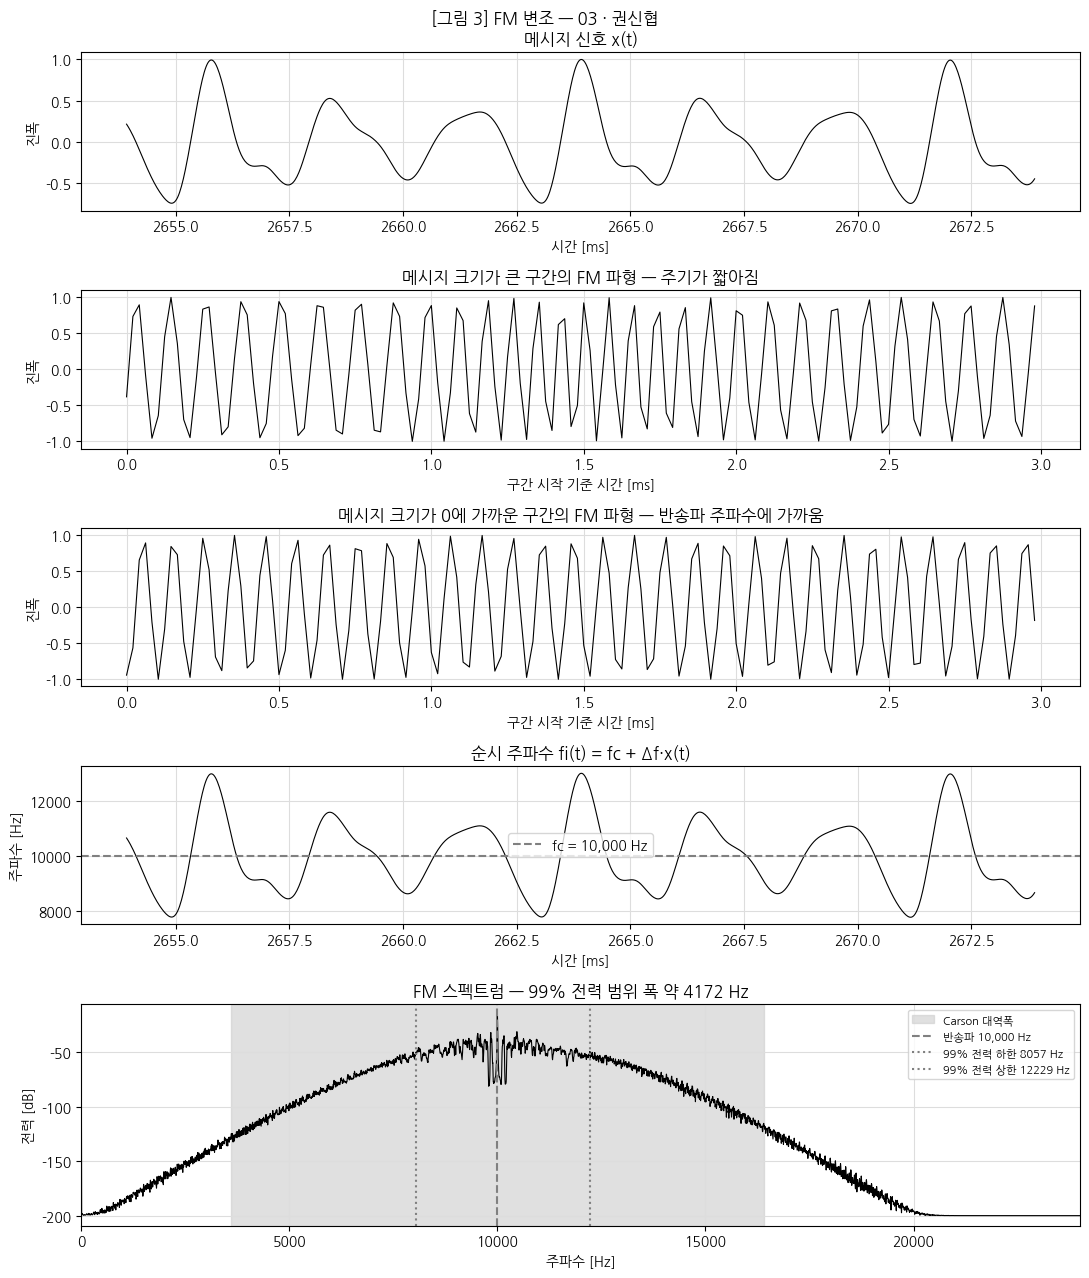

In [9]:
# ===== 4-4. [그림 3] FM 변조 그래프 =====
# 신호가 큰 구간과 작은 구간에서 파형 간격이 달라지는지 비교한다.
win_fm = max(8, min(int(0.003 * Fs_fm), len(msg)))
high_idx = int(np.argmax(np.abs(msg)))
low_idx = int(np.argmin(np.abs(msg)))
high_start = max(0, min(high_idx - win_fm // 2, len(msg) - win_fm))
low_start = max(0, min(low_idx - win_fm // 2, len(msg) - win_fm))

# 20 ms 정도의 음성/순시주파수 구간 표시
seg_fm = min(int(0.02 * Fs_fm), len(msg))
seg_start = max(0, min(high_idx - seg_fm // 2, len(msg) - seg_fm))
seg_end = seg_start + seg_fm

f_fm, P_fm = signal.welch(fm_sig, fs=Fs_fm, nperseg=min(8192, len(fm_sig)))
P_fm_db = 10 * np.log10(P_fm + 1e-20)
cum_power = np.cumsum(P_fm)
cum_power = cum_power / cum_power[-1]
lo_i = int(np.searchsorted(cum_power, 0.005, side='left'))
hi_i = int(np.searchsorted(cum_power, 0.995, side='left'))
f_lo_99 = float(f_fm[min(lo_i, len(f_fm)-1)])
f_hi_99 = float(f_fm[min(hi_i, len(f_fm)-1)])

fig, ax = plt.subplots(5, 1, figsize=(11, 13), gridspec_kw={'height_ratios': [1, 1, 1, 1, 1.4]})
ax[0].plot(t[seg_start:seg_end] * 1000, msg[seg_start:seg_end], 'k', lw=0.8)
ax[0].set_title('메시지 신호 x(t)'); ax[0].set_xlabel('시간 [ms]'); ax[0].set_ylabel('진폭')
ax[1].plot((np.arange(win_fm) / Fs_fm) * 1000, fm_sig[high_start:high_start+win_fm], 'k', lw=0.8)
ax[1].set_title('메시지 크기가 큰 구간의 FM 파형 — 주기가 짧아짐'); ax[1].set_xlabel('구간 시작 기준 시간 [ms]'); ax[1].set_ylabel('진폭')
ax[2].plot((np.arange(win_fm) / Fs_fm) * 1000, fm_sig[low_start:low_start+win_fm], 'k', lw=0.8)
ax[2].set_title('메시지 크기가 0에 가까운 구간의 FM 파형 — 반송파 주파수에 가까움'); ax[2].set_xlabel('구간 시작 기준 시간 [ms]'); ax[2].set_ylabel('진폭')
ax[3].plot(t[seg_start:seg_end] * 1000, fi_fm[seg_start:seg_end], 'k', lw=0.8)
ax[3].axhline(fc_fm, color='0.5', ls='--', label=f'fc = {fc_fm:,} Hz')
ax[3].set_title('순시 주파수 fi(t) = fc + Δf·x(t)'); ax[3].set_xlabel('시간 [ms]'); ax[3].set_ylabel('주파수 [Hz]'); ax[3].legend()
ax[4].plot(f_fm, P_fm_db, 'k', lw=0.8)
ax[4].axvspan(fc_fm - B_carson/2, fc_fm + B_carson/2, color='0.8', alpha=0.6, label='Carson 대역폭')
ax[4].axvline(fc_fm, color='0.5', ls='--', label=f'반송파 {fc_fm:,} Hz')
ax[4].axvline(f_lo_99, color='0.5', ls=':', label=f'99% 전력 하한 {f_lo_99:.0f} Hz')
ax[4].axvline(f_hi_99, color='0.5', ls=':', label=f'99% 전력 상한 {f_hi_99:.0f} Hz')
ax[4].set_xlim(0, Fs_fm / 2)
ax[4].set_title(f'FM 스펙트럼 — 99% 전력 범위 폭 약 {f_hi_99-f_lo_99:.0f} Hz')
ax[4].set_xlabel('주파수 [Hz]'); ax[4].set_ylabel('전력 [dB]'); ax[4].legend(loc='upper right', fontsize=8)
fig.suptitle('[그림 3] FM 변조 — 03 · 권신협')
plt.tight_layout(); plt.show()


### 4-5. FM 결과 기록 📝

| 항목 | 설계값(예상) | 실행 결과 | 일치 여부 / 차이 이유 |
|---|---|---|---|
| β | 3000 / 3400 ≈ 0.88 | 위 셀 출력 | 실제 메시지의 최고 주파수는 음성 대역 상한으로 정한 값 |
| Carson 대역폭 | 2 × (3000 + 3400) = 12800 Hz | 위 셀 출력 및 스펙트럼 | 실제 에너지가 모인 폭은 입력 음성에 따라 달라질 수 있음 |
| 순시 주파수 범위 | 설계 한계 7000~13000 Hz | 위 셀의 이론 범위 | 실제 음성의 양·음 피크가 모두 ±1에 도달하지 않으면 범위가 좁음 |
| 신호 진폭 | 일정, Ac = 1.0 V | 최대 절대 진폭 출력 | 코사인 변조이므로 이산 표본에서는 약 1.0으로 나타남 |


---
## 5. PCM (표본화 → 양자화 → 부호화)

```
 아날로그 m(t) ──▶ [① 표본화 fs] ──▶ [② 양자화 n비트] ──▶ [③ 부호화] ──▶ 0110 1001 0111 …
```

### 5-1. PCM 설계 📝

| 단계 | 항목 | 기호 | 내가 선택한 값 | 단위 | 이 값을 선택한 이유 |
|---|---|---|---:|---|---|
| 표본화 | 표본화 주파수 | fs | 8000 | Hz | 3400 Hz까지의 음성을 다루며 fs ≥ 2×3400 조건을 만족 |
| 양자화 | 양자화 비트 수 | n | 8 | bit | 첨부 PCM 실습의 기본값으로 256개 레벨 사용 |
| 양자화 | 양자화 방식 | - | 균일(선형) | - | 같은 간격의 양자화 레벨을 사용 |
| 양자화 | 진폭 범위 | - | -1.0 ~ +1.0 | - | 메시지 신호를 -1~+1로 정규화 |
| 부호화 | 부호화 방식 | - | 자연 2진 | - | 레벨 번호를 8자리 이진수로 표시 |
| 출력 | 일련 데이터 표시 범위 | - | 1번째 표본부터 20개 | - | 부호화 결과의 앞부분을 확인 |

**설계 단계 예상값 (계산)**

| 항목 | 계산식 | 예상값 | 단위 |
|---|---|---:|---|
| 표본화 주기 | Ts = 1 / fs | 125 | μs |
| 나이퀴스트 율 | 2fm = 2 × 3400 | 6800 | Hz |
| 양자화 레벨 수 | L = 2ⁿ = 2⁸ | 256 | 개 |
| 양자화 간격 | Δ = 2 / L | 0.0078125 | - |
| 이론 SQNR | 6.02n + 1.76 | 49.92 | dB |
| 비트율 | R = fs × n | 64000 | bps |


In [10]:
# ===== 5-2. PCM 파라미터 선언 =====
fs_pcm = 8000      # 표본화 주파수 [Hz]
n_bits = 8         # 양자화 비트 수
q_min = -1.0        # 양자화 진폭 하한
q_max = 1.0         # 양자화 진폭 상한
data_start_sample = 0  # 일련 데이터 출력 시작 표본(0부터 세는 내부 인덱스)
data_show_samples = 20

L_pcm = 2 ** n_bits
delta_pcm = (q_max - q_min) / L_pcm
bit_rate_pcm = fs_pcm * n_bits
nyquist_rate_pcm = 2 * F_HIGH
sqnr_theory_pcm = 6.02 * n_bits + 1.76

print(f'fs_pcm = {fs_pcm:,} Hz, Ts = {1e6/fs_pcm:.1f} μs')
print(f'n_bits = {n_bits} bit, L = 2^{n_bits} = {L_pcm} 레벨')
print(f'진폭 범위 = {q_min:.1f} ~ {q_max:.1f}, 양자화 간격 Δ = {delta_pcm:.7f}')
print(f'나이퀴스트 율 2×F_HIGH = {nyquist_rate_pcm:,} Hz → fs_pcm ≥ 2×F_HIGH: {fs_pcm >= nyquist_rate_pcm}')
print(f'이론 SQNR(최대 크기 사인파 기준) ≈ {sqnr_theory_pcm:.2f} dB')
print(f'비트율 = fs × n = {bit_rate_pcm:,} bps')


fs_pcm = 8,000 Hz, Ts = 125.0 μs
n_bits = 8 bit, L = 2^8 = 256 레벨
진폭 범위 = -1.0 ~ 1.0, 양자화 간격 Δ = 0.0078125
나이퀴스트 율 2×F_HIGH = 6,800 Hz → fs_pcm ≥ 2×F_HIGH: True
이론 SQNR(최대 크기 사인파 기준) ≈ 49.92 dB
비트율 = fs × n = 64,000 bps


원 메시지: 142,303 표본 @ 48,000 Hz
PCM 표본: 23,718 표본 @ 8,000 Hz
표본 간격: 125.0 μs, 표본화율 변환: 1/6


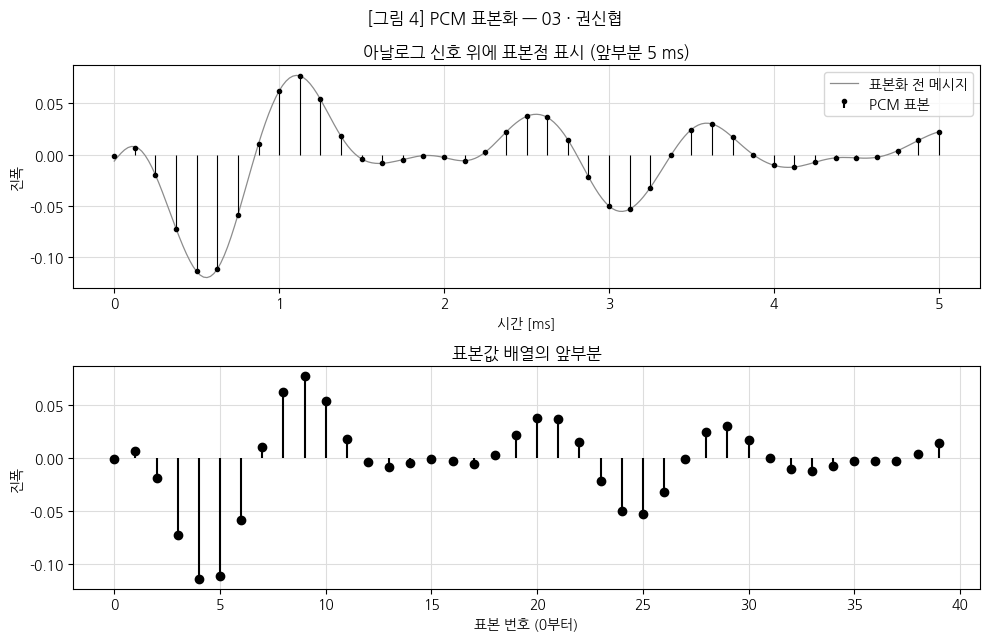

In [11]:
# ===== 5-3. [그림 4] ① 표본화 =====
# 원 신호는 FS=48000 Hz이고 PCM 표본화 주파수는 fs_pcm=8000 Hz이다.
# resample_poly는 표본화율 변환 때 필요한 저역통과 처리를 함께 수행한다.
common_pcm = int(np.gcd(FS, fs_pcm))
up_pcm = fs_pcm // common_pcm
down_pcm = FS // common_pcm
# Nyquist 주파수 아래에 둔 저역통과 필터로 표본화 전 고주파를 제한한다.
cutoff_pcm = min(F_HIGH, fs_pcm * 0.45)
sos_pcm = signal.butter(8, cutoff_pcm, btype='lowpass', fs=FS, output='sos')
msg_pre_pcm = safe_sosfiltfilt(sos_pcm, msg)
x_pcm = signal.resample_poly(msg_pre_pcm, up_pcm, down_pcm)
t_pcm = np.arange(len(x_pcm)) / fs_pcm

print(f'원 메시지: {len(msg):,} 표본 @ {FS:,} Hz')
print(f'PCM 표본: {len(x_pcm):,} 표본 @ {fs_pcm:,} Hz')
print(f'표본 간격: {1e6/fs_pcm:.1f} μs, 표본화율 변환: {up_pcm}/{down_pcm}')

plot_ms = min(5.0, len(msg) / FS * 1000)
analog_mask = t <= plot_ms / 1000
sample_mask = t_pcm <= plot_ms / 1000
fig, ax = plt.subplots(2, 1, figsize=(10, 6.5))
ax[0].plot(t[analog_mask] * 1000, msg_pre_pcm[analog_mask], color='0.55', lw=0.9, label='표본화 전 메시지')
markerline, stemlines, baseline = ax[0].stem(t_pcm[sample_mask] * 1000, x_pcm[sample_mask],
                                             linefmt='k-', markerfmt='ko', basefmt=' ', label='PCM 표본')
plt.setp(stemlines, linewidth=0.8); plt.setp(markerline, markersize=3)
ax[0].set_title('아날로그 신호 위에 표본점 표시 (앞부분 5 ms)')
ax[0].set_xlabel('시간 [ms]'); ax[0].set_ylabel('진폭'); ax[0].legend(loc='upper right')
ax[1].stem(np.arange(min(40, len(x_pcm))), x_pcm[:40], linefmt='k-', markerfmt='ko', basefmt=' ')
ax[1].set_title('표본값 배열의 앞부분')
ax[1].set_xlabel('표본 번호 (0부터)'); ax[1].set_ylabel('진폭')
fig.suptitle('[그림 4] PCM 표본화 — 03 · 권신협')
plt.tight_layout(); plt.show()


양자화 레벨 수 L = 256
단계 번호 범위 = 26 ~ 254
양자화 값 범위 = -0.7930 ~ 0.9883
양자화 오차 범위 = -0.003906 ~ 0.003906
측정 SQNR = 38.05 dB (이론 참고값 49.92 dB)


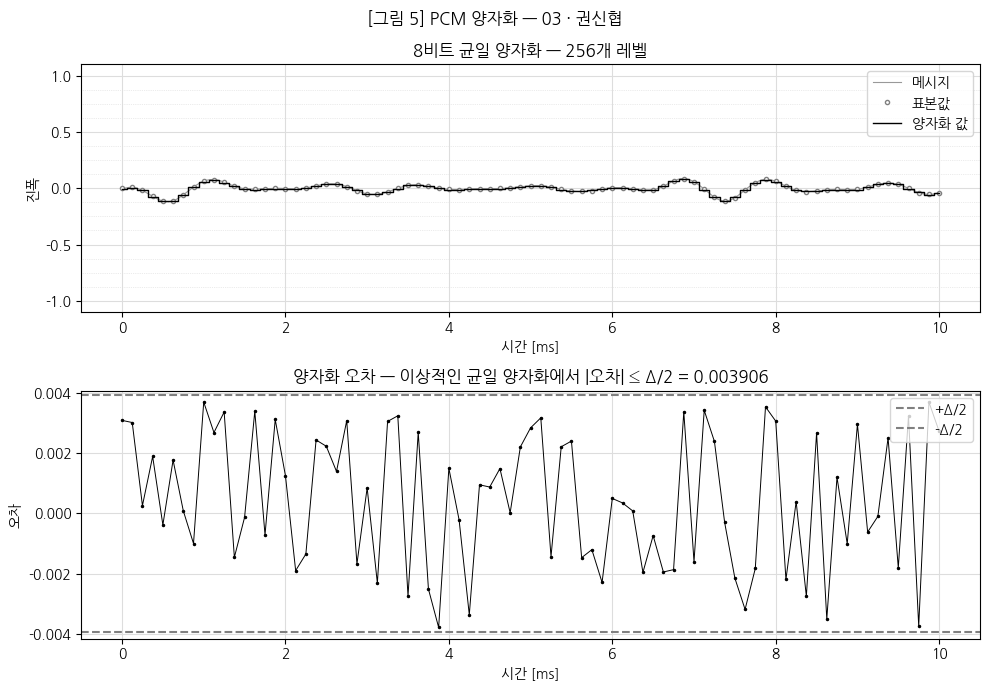

In [12]:
# ===== 5-4. [그림 5] ② 양자화 =====
# 균일(mid-rise) 양자화: [-1, 1] 범위를 L개 구간으로 나누어 단계 번호를 만든다.
idx_pcm = np.clip(np.floor((x_pcm - q_min) / delta_pcm), 0, L_pcm - 1).astype(int)
q_pcm = q_min + (idx_pcm + 0.5) * delta_pcm
quant_error = x_pcm - q_pcm
signal_power = float(np.sum(x_pcm ** 2))
noise_power = float(np.sum(quant_error ** 2))
sqnr_measured_pcm = 10 * np.log10((signal_power + 1e-20) / (noise_power + 1e-20))

print(f'양자화 레벨 수 L = {L_pcm}')
print(f'단계 번호 범위 = {idx_pcm.min()} ~ {idx_pcm.max()}')
print(f'양자화 값 범위 = {q_pcm.min():.4f} ~ {q_pcm.max():.4f}')
print(f'양자화 오차 범위 = {quant_error.min():.6f} ~ {quant_error.max():.6f}')
print(f'측정 SQNR = {sqnr_measured_pcm:.2f} dB (이론 참고값 {sqnr_theory_pcm:.2f} dB)')

quant_show_sec = min(0.01, len(x_pcm) / fs_pcm)
qmask = t_pcm <= quant_show_sec
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
analog_qmask = t <= quant_show_sec
ax[0].plot(t[analog_qmask] * 1000, msg_pre_pcm[analog_qmask], color='0.6', lw=0.8, label='메시지')
ax[0].plot(t_pcm[qmask] * 1000, x_pcm[qmask], 'o', ms=3, mfc='white', color='gray', label='표본값')
ax[0].step(t_pcm[qmask] * 1000, q_pcm[qmask], where='mid', color='black', lw=1, label='양자화 값')
# 모든 레벨선을 그리는 대신 16개 단위 주요 레벨 경계를 표시해 가독성을 유지한다.
for level in range(0, L_pcm + 1, max(1, L_pcm // 16)):
    ax[0].axhline(q_min + level * delta_pcm, color='0.85', ls=':', lw=0.5, zorder=0)
ax[0].set_title(f'8비트 균일 양자화 — {L_pcm}개 레벨')
ax[0].set_xlabel('시간 [ms]'); ax[0].set_ylabel('진폭'); ax[0].legend(loc='upper right')
ax[1].plot(t_pcm[qmask] * 1000, quant_error[qmask], 'k.-', ms=3, lw=0.7)
ax[1].axhline(delta_pcm / 2, color='0.5', ls='--', label='+Δ/2')
ax[1].axhline(-delta_pcm / 2, color='0.5', ls='--', label='-Δ/2')
ax[1].set_title(f'양자화 오차 — 이상적인 균일 양자화에서 |오차| ≤ Δ/2 = {delta_pcm/2:.6f}')
ax[1].set_xlabel('시간 [ms]'); ax[1].set_ylabel('오차'); ax[1].legend(loc='upper right')
fig.suptitle('[그림 5] PCM 양자화 — 03 · 권신협')
plt.tight_layout(); plt.show()


   표본 번호     시간(ms)        표본값     레벨       양자화값      2진 부호
       1      0.000    -0.0008    127    -0.0039   01111111
       2      0.125     0.0069    128     0.0039   10000000
       3      0.250    -0.0193    125    -0.0195   01111101
       4      0.375    -0.0723    118    -0.0742   01110110
       5      0.500    -0.1137    113    -0.1133   01110001
       6      0.625    -0.1115    113    -0.1133   01110001
       7      0.750    -0.0585    120    -0.0586   01111000
       8      0.875     0.0107    129     0.0117   10000001
       9      1.000     0.0623    135     0.0586   10000111
      10      1.125     0.0769    137     0.0742   10001001
전체 표본 수 = 23,718, 전체 비트 수 = 189,744
비트율 = 8,000 × 8 = 64,000 bps


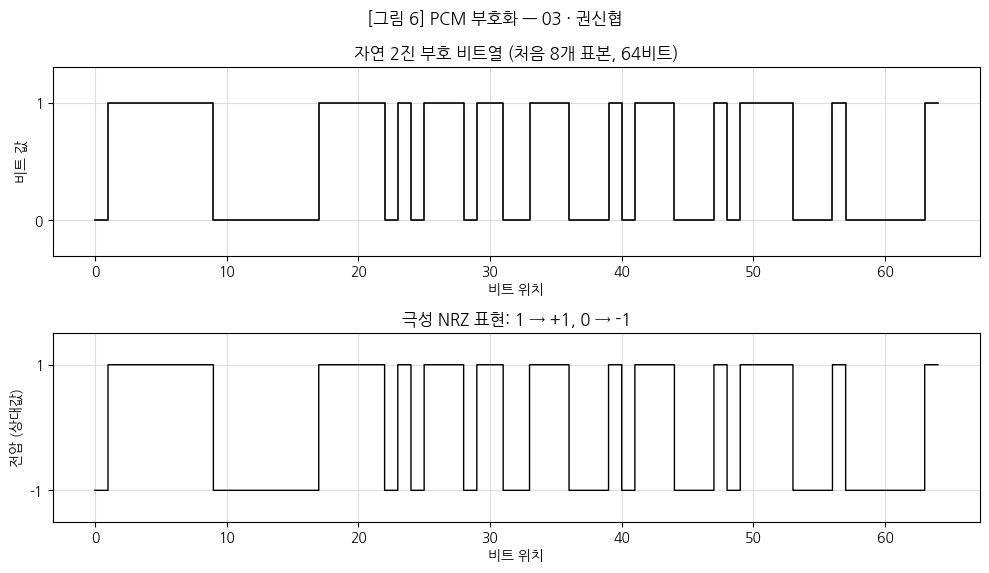

In [13]:
# ===== 5-5. [그림 6] ③ 부호화 =====
codes_pcm = [format(int(level), f'0{n_bits}b') for level in idx_pcm]
bit_matrix_pcm = ((idx_pcm[:, None] >> np.arange(n_bits - 1, -1, -1)) & 1).astype(np.uint8)
bits_pcm = bit_matrix_pcm.ravel()

n_table = min(10, len(idx_pcm))
print(f"{'표본 번호':>8} {'시간(ms)':>10} {'표본값':>10} {'레벨':>6} {'양자화값':>10} {'2진 부호':>10}")
for k in range(n_table):
    print(f'{k+1:8d} {t_pcm[k]*1000:10.3f} {x_pcm[k]:10.4f} {idx_pcm[k]:6d} {q_pcm[k]:10.4f} {codes_pcm[k]:>10}')
print(f'전체 표본 수 = {len(idx_pcm):,}, 전체 비트 수 = {len(bits_pcm):,}')
print(f'비트율 = {fs_pcm:,} × {n_bits} = {bit_rate_pcm:,} bps')

shown_samples = min(8, len(idx_pcm))
shown_bits = bits_pcm[:shown_samples * n_bits]
spb_pcm = 8
nrz_pcm = np.repeat(2.0 * shown_bits.astype(float) - 1.0, spb_pcm)
bit_axis = np.arange(len(nrz_pcm) + 1) / spb_pcm
nrz_for_step = np.append(nrz_pcm, nrz_pcm[-1]) if len(nrz_pcm) else np.array([0.0])
fig, ax = plt.subplots(2, 1, figsize=(10, 5.8))
ax[0].step(np.arange(len(shown_bits) + 1), np.append(shown_bits, shown_bits[-1]) if len(shown_bits) else np.array([0]),
           where='post', color='black', lw=1.2)
ax[0].set_title(f'자연 2진 부호 비트열 (처음 {shown_samples}개 표본, {len(shown_bits)}비트)')
ax[0].set_xlabel('비트 위치'); ax[0].set_ylabel('비트 값'); ax[0].set_yticks([0, 1]); ax[0].set_ylim(-0.3, 1.3)
ax[1].step(bit_axis, nrz_for_step, where='post', color='black', lw=1.0)
ax[1].set_title('극성 NRZ 표현: 1 → +1, 0 → -1')
ax[1].set_xlabel('비트 위치'); ax[1].set_ylabel('전압 (상대값)'); ax[1].set_yticks([-1, 1]); ax[1].set_ylim(-1.5, 1.5)
fig.suptitle('[그림 6] PCM 부호화 — 03 · 권신협')
plt.tight_layout(); plt.show()


In [14]:
# ===== 5-6. 부호화 일련 데이터 출력 =====
start_sample = min(max(int(data_start_sample), 0), len(codes_pcm))
end_sample = min(start_sample + int(data_show_samples), len(codes_pcm))
selected_codes = codes_pcm[start_sample:end_sample]
serial_bits_pcm = ''.join(selected_codes)

print(f'표본 {start_sample + 1}번부터 {len(selected_codes)}개 표본의 부호')
print('표본 단위:', ' '.join(selected_codes))
print('연속 비트열:', serial_bits_pcm)
print(f'출력 표본 수 = {len(selected_codes)}개')
print(f'출력 비트 수 = {len(serial_bits_pcm)} bit ({len(selected_codes)} × {n_bits})')


# ===== 자동 검증: 길이·범위·계산식 확인 =====
assert len(msg) == len(t) == len(am) == len(fm_sig), 'AM/FM 신호 길이가 일치하지 않습니다.'
assert FC + fm < FS / 2, 'AM 반송파와 메시지의 합이 나이퀴스트 한계를 넘습니다.'
assert fc_fm + df_fm + fm_fm < Fs_fm / 2, 'FM 최대 주파수가 나이퀴스트 한계를 넘습니다.'
assert np.all(np.isfinite(am)) and np.all(np.isfinite(fm_sig)), 'AM/FM 신호에 비유한 값이 있습니다.'
assert np.all((idx_pcm >= 0) & (idx_pcm < L_pcm)), '양자화 레벨 번호 범위를 벗어났습니다.'
assert np.max(np.abs(quant_error)) <= delta_pcm / 2 + 1e-12, '양자화 오차가 ±Δ/2 범위를 벗어났습니다.'
assert len(bits_pcm) == len(idx_pcm) * n_bits, '비트열 길이가 표본 수 × 비트 수와 다릅니다.'
assert all(len(code) == n_bits for code in codes_pcm), '일부 부호의 자릿수가 n_bits와 다릅니다.'
assert len(serial_bits_pcm) == len(selected_codes) * n_bits, '출력 비트열 길이가 출력 표본 수와 다릅니다.'
print('자동 검증 통과: AM/FM 샘플링·신호 길이, 유한한 신호값, PCM 레벨/오차/부호 길이 모두 정상입니다.')


표본 1번부터 20개 표본의 부호
표본 단위: 01111111 10000000 01111101 01110110 01110001 01110001 01111000 10000001 10000111 10001001 10000110 10000010 01111111 01111110 01111111 01111111 01111111 01111111 10000000 10000010
연속 비트열: 0111111110000000011111010111011001110001011100010111100010000001100001111000100110000110100000100111111101111110011111110111111101111111011111111000000010000010
출력 표본 수 = 20개
출력 비트 수 = 160 bit (20 × 8)
자동 검증 통과: AM/FM 샘플링·신호 길이, 유한한 신호값, PCM 레벨/오차/부호 길이 모두 정상입니다.


### 5-7. PCM 결과 기록 📝

| 항목 | 설계값(예상) | 실행 결과 | 일치 여부 / 차이 이유 |
|---|---|---|---|
| 표본화 주파수 / 표본 수 | 8000 Hz / 입력 길이에 따라 결정 | 5-3 출력 | 입력 음성 길이가 달라지면 표본 수가 달라짐 |
| 양자화 레벨 수 L | 256개 | 5-4 출력 | n=8이므로 2⁸=256 |
| SQNR | 이론 참고값 49.92 dB | 5-4의 측정값 | 음성의 진폭 분포에 따라 이론값과 다름 |
| 비트율 / 전체 비트 수 | 64000 bps / 표본 수 × 8 | 5-5 출력 | 전체 비트 수는 입력 음성 길이에 비례 |

**부호화 일련 데이터 (5-6 출력 붙여넣기)**

아래 셀의 `표본 단위` 및 `연속 비트열` 출력을 이 위치에 기록합니다.


---
## ✅ 제출 전 체크리스트
- [ ] 번호, 이름을 작성했다.
- [ ] 본인 음성을 녹음/업로드했거나, 실습 확인을 위해 내부 합성 음성을 사용했다.
- [ ] 설계표와 코드의 파라미터가 일치한다.
- [ ] [그림 1]~[그림 6] 그래프가 출력되고 제목에 번호·이름이 있다.
- [ ] AM 포락선 및 측정 변조지수, FM 순시 주파수·Carson 대역폭, PCM SQNR·부호화 데이터가 출력되었다.
- [ ] 결과 기록표와 고찰을 작성했다.
- [ ] 런타임 → 모두 실행으로 셀을 순서대로 실행하고 오류 없이 저장했다.
